In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    print("GPU not available; using CPU")
    device = torch.device("cpu")

print("Selected device:", device)

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Selected device: cuda


### Google Drive connect karo

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Project folders create karo

In [15]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Face Mask Detection"

folders = [
    "dataset",
    "models",
    "results",
    "notebooks"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_PATH, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


### Check Dataset

In [16]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', 'Face Mask Detection']


In [18]:
import os

print("\nFace Mask Detection:")
print(os.listdir("/content/drive/MyDrive/Face Mask Detection"))


Face Mask Detection:
['archive (1).zip', 'archive (1)', 'dataset', 'models', 'results', 'notebooks']


In [19]:
import os

dataset_path = "/content/drive/MyDrive/Face Mask Detection/dataset"

print("Dataset path exists:", os.path.exists(dataset_path))
print("Contents:", os.listdir(dataset_path))

Dataset path exists: True
Contents: []


In [20]:
import os

base = "/content/drive/MyDrive/Face Mask Detection/archive (1)"

print("Exists:", os.path.exists(base))
print("Contents:")
print(os.listdir(base))

Exists: True
Contents:
['data']


In [21]:
for item in os.listdir(base):
    path = os.path.join(base, item)
    if os.path.isdir(path):
        print(f"\n{item}:")
        print(os.listdir(path)[:10])   # First 10 items


data:
['without_mask', 'with_mask']


In [22]:
import shutil
import os

src = "/content/drive/MyDrive/Face Mask Detection/archive (1)/data"
dst = "/content/drive/MyDrive/Face Mask Detection/dataset"

shutil.copytree(src, dst, dirs_exist_ok=True)

print(" Dataset copied successfully!")

✅ Dataset copied successfully!


In [23]:
import os

dataset_path = "/content/drive/MyDrive/Face Mask Detection/dataset"

print("Classes:", os.listdir(dataset_path))

for cls in os.listdir(dataset_path):
    cls_path = os.path.join(dataset_path, cls)
    print(f"{cls}: {len(os.listdir(cls_path))} images")

Classes: ['without_mask', 'with_mask']
without_mask: 3828 images
with_mask: 3725 images


### Import Libraries

In [24]:
import torch
import torchvision
import matplotlib.pyplot as plt

from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader
from torch.utils.data import random_split

print("PyTorch :", torch.__version__)
print("Torchvision :", torchvision.__version__)

PyTorch : 2.11.0+cu130
Torchvision : 0.26.0+cu130


In [25]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cuda


### Image Preprocessing

In [27]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### Load Dataset

In [28]:
dataset_path = "/content/drive/MyDrive/Face Mask Detection/dataset"

dataset = datasets.ImageFolder(
    root=dataset_path,
    transform=transform
)

print("Total Images :", len(dataset))
print("Classes :", dataset.classes)
print("Class Mapping :", dataset.class_to_idx)

Total Images : 7553
Classes : ['with_mask', 'without_mask']
Class Mapping : {'with_mask': 0, 'without_mask': 1}


### Train-Validation Split

In [29]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size]
)

print("Training Images   :", len(train_dataset))
print("Validation Images :", len(val_dataset))

Training Images   : 6042
Validation Images : 1511


### Create DataLoader

In [30]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Train Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))

Train Batches : 189
Validation Batches : 48


### Check One Batch

In [31]:
images, labels = next(iter(train_loader))

print("Images Shape :", images.shape)
print("Labels Shape :", labels.shape)

print(labels)

Images Shape : torch.Size([32, 3, 224, 224])
Labels Shape : torch.Size([32])
tensor([1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
        1, 0, 1, 1, 0, 1, 0, 1])


### Visualize Batch

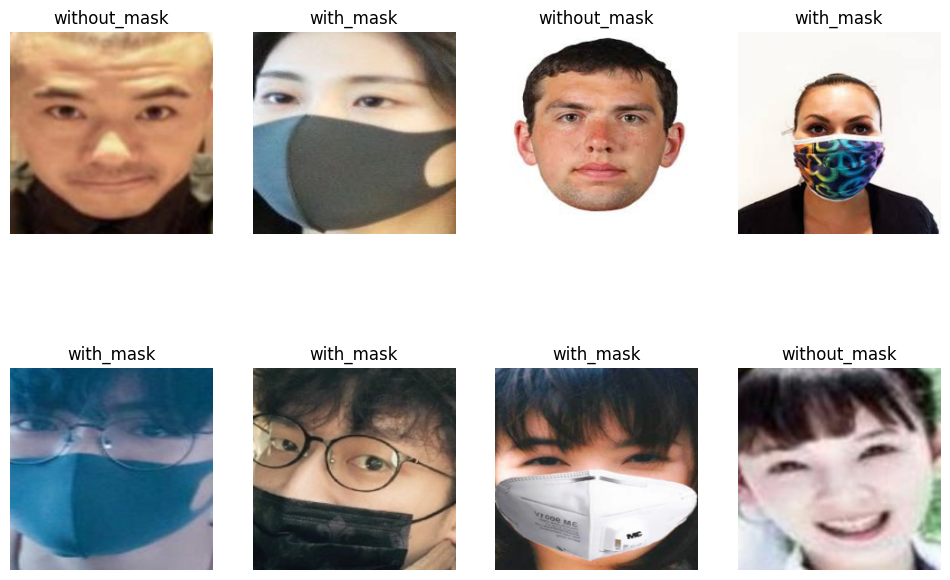

In [32]:
import matplotlib.pyplot as plt

class_names = dataset.classes

plt.figure(figsize=(12,8))

for i in range(8):

    plt.subplot(2,4,i+1)

    img = images[i].permute(1,2,0)

    img = img * torch.tensor([0.229,0.224,0.225]) + torch.tensor([0.485,0.456,0.406])

    img = img.clamp(0,1)

    plt.imshow(img)

    plt.title(class_names[labels[i]])

    plt.axis("off")

plt.show()

### CNN Model

In [33]:
import torch.nn as nn

class FaceMaskCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)

        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 28 * 28, 512),
            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(512, 2)

        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x

Create Model

In [34]:
model = FaceMaskCNN().to(device)

print(model)

FaceMaskCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=2, bias=True)
  )
)


### Loss Function & Optimizer

In [36]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)



### Training Function

In [38]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()   # Training mode

    running_loss = 0.0
    correct = 0
    total = 0


    for images, labels in train_loader:

        # Move data to GPU/CPU
        images = images.to(device)
        labels = labels.to(device)


        # Forward pass
        outputs = model(images)


        # Calculate loss
        loss = criterion(outputs, labels)


        # Clear old gradients
        optimizer.zero_grad()


        # Backpropagation
        loss.backward()


        # Update weights
        optimizer.step()



        # Loss calculation
        running_loss += loss.item()


        # Accuracy calculation
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()



    epoch_loss = running_loss / len(train_loader)

    epoch_accuracy = 100 * correct / total


    return epoch_loss, epoch_accuracy

### Validation Function

In [39]:
def validate(model, val_loader, criterion, device):

    model.eval()   # Evaluation mode


    running_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():

        for images, labels in val_loader:


            images = images.to(device)
            labels = labels.to(device)


            outputs = model(images)


            loss = criterion(outputs, labels)


            running_loss += loss.item()



            _, predicted = torch.max(outputs.data, 1)


            total += labels.size(0)

            correct += (predicted == labels).sum().item()



    val_loss = running_loss / len(val_loader)

    val_accuracy = 100 * correct / total


    return val_loss, val_accuracy

### Run Training + Validation

In [40]:
EPOCHS = 10

train_losses = []
val_losses = []

train_accs = []
val_accs = []


for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )


    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion,
        device
    )


    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)


    print(
        f"Epoch {epoch+1}/{EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.2f}%"
    )

    print("----------------------")

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/10
Train Loss: 0.4088 | Train Accuracy: 84.94%
Val Loss: 0.2398 | Val Accuracy: 88.75%
----------------------


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 2/10
Train Loss: 0.2224 | Train Accuracy: 90.55%
Val Loss: 0.1976 | Val Accuracy: 90.87%
----------------------


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch 8/10
Train Loss: 0.0324 | Train Accuracy: 99.01%
Val Loss: 0.1773 | Val Accuracy: 94.84%
----------------------


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 9/10
Train Loss: 0.0288 | Train Accuracy: 99.09%
Val Loss: 0.1738 | Val Accuracy: 95.30%
----------------------


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 10/10
Train Loss: 0.0243 | Train Accuracy: 99.19%
Val Loss: 0.2360 | Val Accuracy: 93.45%
----------------------


### Save Best Model

In [41]:
import os

model_path = "/content/drive/MyDrive/Face Mask Detection/models"

os.makedirs(model_path, exist_ok=True)


torch.save(
    model.state_dict(),
    os.path.join(model_path, "best_face_mask_model.pth")
)


print("Model saved successfully!")

Model saved successfully!


### Training Curves Plot

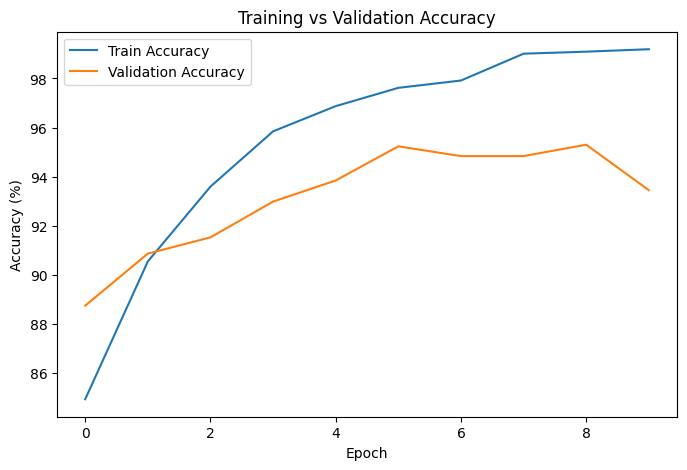

In [42]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8,5))

plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.show()

### Loss graph:

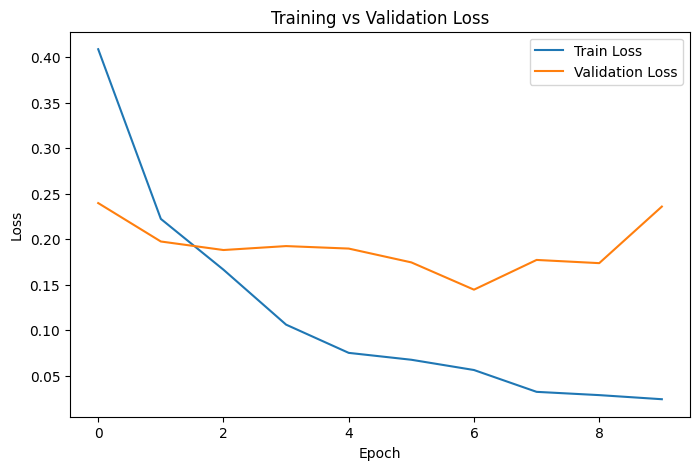

In [43]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()

plt.show()

### Load Saved Model

In [44]:
import torch

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Face Mask Detection/models/best_face_mask_model.pth",
        map_location=device
    )
)

model.to(device)

model.eval()

print("Model loaded successfully!")

Model loaded successfully!


### Single Image Prediction

In [46]:
from PIL import Image
import matplotlib.pyplot as plt


def predict_image(image_path):

    image = Image.open(image_path).convert("RGB")

    img = transform(image).unsqueeze(0)

    img = img.to(device)


    with torch.no_grad():

        output = model(img)

        _, predicted = torch.max(output,1)


    class_name = dataset.classes[predicted.item()]


    plt.imshow(image)

    plt.title(
        f"Prediction: {class_name}"
    )

    plt.axis("off")

    plt.show()


    return class_name

### Test Image Path

In [47]:
import os


img_path = "/content/drive/MyDrive/Face Mask Detection/dataset/with_mask"

image_name = os.listdir(img_path)[0]


test_image = os.path.join(
    img_path,
    image_name
)


print(test_image)

/content/drive/MyDrive/Face Mask Detection/dataset/with_mask/with_mask_548.jpg


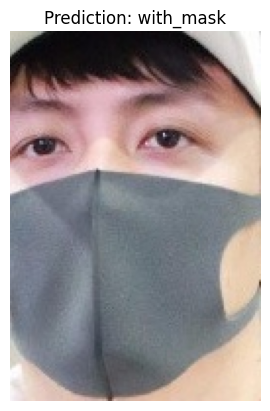

'with_mask'

In [48]:
predict_image(test_image)

### Confusion Matrix

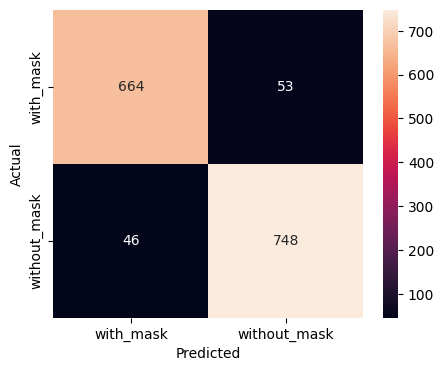

In [49]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


all_labels = []
all_predictions = []


model.eval()


with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)


        outputs = model(images)


        _, predicted = torch.max(outputs,1)


        all_labels.extend(
            labels.cpu().numpy()
        )


        all_predictions.extend(
            predicted.cpu().numpy()
        )


cm = confusion_matrix(
    all_labels,
    all_predictions
)


plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

### Classification report

In [50]:
from sklearn.metrics import classification_report


print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=dataset.classes
    )
)

              precision    recall  f1-score   support

   with_mask       0.94      0.93      0.93       717
without_mask       0.93      0.94      0.94       794

    accuracy                           0.93      1511
   macro avg       0.93      0.93      0.93      1511
weighted avg       0.93      0.93      0.93      1511



In [52]:
import os

project_path = "/content/drive/MyDrive/Face Mask Detection"

folders = [
    "app",
    "models",
    "notebooks",
    "results"
]


for folder in folders:
    os.makedirs(
        os.path.join(project_path, folder),
        exist_ok=True
    )


print("Folders created successfully!")

Folders created successfully!
